# x axis — identification and cascade controller (advanced tasks: land elsewhere, then on the moving vehicle)

**What we know from `explore_x.m`** (the drone hovers, one motor gets +0.02 for 0.5 s):
- motors 1 and 3 are on the x axis: pushing 3 more than 1 tilts the drone forward (pitch θ > 0) and it goes towards +x;
  motors 2 and 4 do the same on y (roll φ); the pairs 1-3 and 2-4 also make the drone turn on itself (yaw), in opposite directions.
- **x command:** u1 = u_z − δ, u3 = u_z + δ, u2 = u4 = u_z. The total thrust and the yaw do not change; only the pitch does.
- the pitch has no natural restoring force: open loop, the drone tilts more and more (it flipped in the test). It needs a fast loop
  that holds the angle.

**This notebook:** (1) identify the pitch dynamics from the data, (2) check how the tilt moves the drone in x, (3) tune a cascade
controller (angle loop + position loop) on the identified model. No training: everything runs in a few seconds.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# explore_x.csv, written by explore_x.m (Student_folder\Student_folder\Matlab files) -> change the path if needed
EXPLORE_CSV = r'C:\Users\ezabl\Downloads\Student_folder\Student_folder\Matlab files\explore_x.csv'

R = np.loadtxt(EXPLORE_CSV, delimiter=',')      # columns: test number, t, then the 18 outputs of UAV_model
NAMES = ['x', 'y', 'z', 'vx', 'vy', 'vz', 'ax', 'ay', 'az', 'phi', 'theta', 'psi', 'wx', 'wy', 'wz', 'w_dot_x', 'w_dot_y', 'w_dot_z']
def signal(test, name):
    rows = R[:, 0] == test
    return R[rows, 1], R[rows, 2 + NAMES.index(name)]

# Constants identified in notebooks 01-02 (vertical axis)
Ts, U_HOVER = 0.05, 0.389
A_M, B_M = 0.7787, 0.2231     # motor state x_m(k+1) = A_M x_m(k) + B_M u(k)   (time constant 0.2 s)
C_T = 0.992                   # thrust of one motor ~ tanh(C_T x_m)
A_T, G = 26.67, 9.81          # az = A_T * mean(tanh(C_T x_m)) - G   (4 motors)

## 1. Pitch dynamics

Model to identify: the angular acceleration in pitch is proportional to the **difference of thrust** between motors 3 and 1:
$$\dot\omega_y = K\,\big(\tanh(c\,x_{m,3}) - \tanh(c\,x_{m,1})\big)$$
where $x_{m,i}$ is the state of motor i (same first order as in notebook 01, computed from the commands of the test).
One unknown, K, found by least squares on tests 1 and 3, during the pulse (1.0 s to 1.6 s, small angles).

K = 100.00 rad/s^2   (residual std 1.1e-04 rad/s^2: the model is exact)


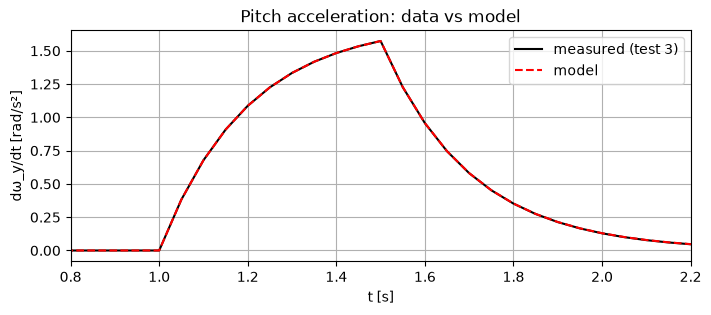

In [2]:
def motor_states(U):
    """Motor states from the commands U (time x 4), with the first order of notebook 01."""
    X = np.zeros_like(U)
    for k in range(1, len(U)):
        X[k] = A_M * X[k - 1] + B_M * U[k - 1]
    return X

regressor, target = [], []
for test in (1, 3):                                   # the tests that excite the pitch
    t, wdot = signal(test, 'w_dot_y')
    U = U_HOVER * np.ones((len(t), 4))
    U[(t >= 1.0 - 1e-9) & (t < 1.5 - 1e-9), test - 1] += 0.02       # the pulse of explore_x.m
    F = np.tanh(C_T * motor_states(U))
    window = (t >= 1.0) & (t <= 1.6)
    regressor.append(F[window, 2] - F[window, 0]); target.append(wdot[window])
regressor, target = np.concatenate(regressor), np.concatenate(target)
K = np.linalg.lstsq(regressor[:, None], target, rcond=None)[0][0]
print(f'K = {K:.2f} rad/s^2   (residual std {np.std(target - K * regressor):.1e} rad/s^2: the model is exact)')

t, wdot = signal(3, 'w_dot_y')
U = U_HOVER * np.ones((len(t), 4)); U[(t >= 1.0 - 1e-9) & (t < 1.5 - 1e-9), 2] += 0.02
F = np.tanh(C_T * motor_states(U))
plt.figure(figsize=(8, 3)); plt.plot(t, wdot, 'k', label='measured (test 3)'); plt.plot(t, K * (F[:, 2] - F[:, 0]), 'r--', label='model')
plt.xlim(0.8, 2.2); plt.xlabel('t [s]'); plt.ylabel('dω_y/dt [rad/s²]'); plt.grid(); plt.legend(); plt.title('Pitch acceleration: data vs model'); plt.show()

## 2. From the tilt to the motion in x

The thrust is along the axis of the drone: when it tilts by θ, its horizontal component accelerates the drone:
$a_x = (a_z + g)\tan\theta$ ($a_z + g$ = vertical acceleration given by the thrust). Checked on test 3 (1 s to 2 s):

In [3]:
t, th = signal(3, 'theta'); _, ax = signal(3, 'ax'); _, az = signal(3, 'az')
w = (t >= 1.0) & (t <= 2.0)
ratio = np.linalg.lstsq(((az[w] + G) * np.tan(th[w]))[:, None], ax[w], rcond=None)[0][0]
print(f'a_x / ((a_z + g) tan(theta)) = {ratio:.3f}   (1 = the model holds)')

a_x / ((a_z + g) tan(theta)) = 0.981   (1 = the model holds)


## 3. Cascade controller, tuned on the identified model

- **Angle loop (fast):** $\delta = K_\theta(\theta_{ref} - \theta) - K_\omega\,\omega_y$, bounded to ±0.1.
- **Position loop (slow):** $\theta_{ref} = k_x(x_{ref} - x) - k_v\,v_x$, bounded to ±0.2 rad (11°): small angles, the height loop is
  barely disturbed (cos 0.2 = 0.98).

The model is simulated finely (10 sub-steps per Ts, the controller acting every Ts as in Simulink), the height being held at hover.
The gains are chosen by a grid search on a 1 m move over 10 s, **for K × 0.7, 1 and 1.3 at the same time** (the identified model is never
perfect): the worst case must have a small error, a small overshoot and **no oscillation of the angle at the end**. Aggressive gains
look good on 6 s but start to oscillate later: this is why the flight is simulated for the whole 10 s of the mission.

chosen gains (K_theta, K_omega, k_x, k_v) = (0.1, 0.04, 0.1, 0.15)
overshoot 3.3 cm | error 4 s after the start 2.0 cm | max angle 0.112 rad


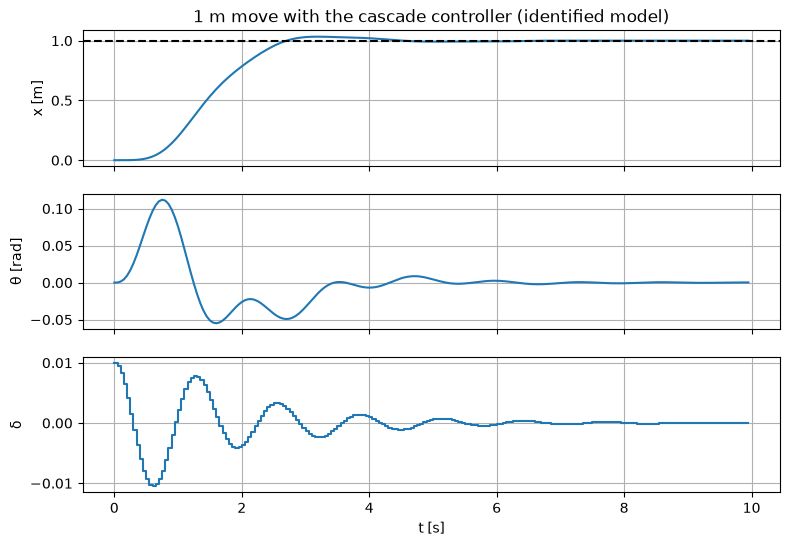

In [4]:
def simulate_x(gains, x_ref=1.0, T=10.0, K=K, th_max=0.2, d_max=0.1, sub=10):
    """Move from x = 0 to x_ref with the cascade controller, on the identified model. Returns t, x, theta, delta."""
    Kt, Kw, kx, kv = gains
    tau, gain = -Ts / np.log(A_M), B_M / (1 - A_M)            # continuous first order of the motors
    xm = np.full(4, U_HOVER * gain)                             # motors at hover
    th = om = x = vx = 0.0
    log = []
    for k in range(int(T / Ts)):
        th_ref = np.clip(kx * (x_ref - x) - kv * vx, -th_max, th_max)    # position loop
        d = np.clip(Kt * (th_ref - th) - Kw * om, -d_max, d_max)         # angle loop
        u = np.array([U_HOVER - d, U_HOVER, U_HOVER + d, U_HOVER])
        log.append((k * Ts, x, th, d))
        for _ in range(sub):
            dt = Ts / sub
            xm += dt * (gain * u - xm) / tau
            F = np.tanh(C_T * xm)
            om += dt * K * (F[2] - F[0]); th += dt * om
            vx += dt * A_T * F.mean() * np.sin(th); x += dt * vx
    return np.array(log).T

def cost(gains):
    """Worst case over K x 0.7, 1, 1.3: error 4 s after the start, overshoot, error and angle oscillation in the last 4 s."""
    worst = 0.0
    for factor in (0.7, 1.0, 1.3):
        t, x, th, d = simulate_x(gains, K=K * factor)
        if not np.all(np.isfinite(x)) or np.abs(th).max() > 0.25:
            return np.inf
        late = t >= 6
        c = abs(x[t >= 4][0] - 1) + max(x.max() - 1, 0) + np.mean(np.abs(x[late] - 1)) + 5 * np.std(th[late])
        worst = max(worst, c)
    return worst

results = []
for Kt in [0.05, 0.08, 0.1, 0.15, 0.2]:
    for Kw in [0.02, 0.03, 0.04, 0.06]:
        for kx in [0.1, 0.15, 0.2]:
            for kv in [0.15, 0.2, 0.3]:
                results.append((cost((Kt, Kw, kx, kv)), (Kt, Kw, kx, kv)))
GAINS = min(results)[1]
print('chosen gains (K_theta, K_omega, k_x, k_v) =', GAINS)

t, x, th, d = simulate_x(GAINS)
print(f'overshoot {max(x.max() - 1, 0) * 100:.1f} cm | error 4 s after the start {abs(x[t >= 4][0] - 1) * 100:.1f} cm | max angle {np.abs(th).max():.3f} rad')
fig, ax = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
ax[0].plot(t, x); ax[0].axhline(1, ls='--', c='k'); ax[0].set_ylabel('x [m]')
ax[1].plot(t, th); ax[1].set_ylabel('θ [rad]'); ax[2].step(t, d, where='post'); ax[2].set_ylabel('δ'); ax[2].set_xlabel('t [s]')
for a in ax: a.grid()
ax[0].set_title('1 m move with the cascade controller (identified model)'); plt.show()

**Robustness:** the same gains with K changed by ±30 % (the identified model is never perfect):

In [5]:
for factor in (0.7, 1.0, 1.3):
    t, x, th, d = simulate_x(GAINS, K=K * factor)
    print(f'K x {factor}: overshoot {max(x.max() - 1, 0) * 100:4.1f} cm | final error {abs(x[-1] - 1) * 100:4.1f} cm | max angle {np.abs(th).max():.3f} rad')

K x 0.7: overshoot  3.5 cm | final error  0.1 cm | max angle 0.116 rad
K x 1.0: overshoot  3.3 cm | final error  0.0 cm | max angle 0.112 rad
K x 1.3: overshoot  4.5 cm | final error  0.0 cm | max angle 0.108 rad
